# Deep Q-Network (DQN) no Atari Breakout

Adaptado do exemplo do Keras de [Jacob Chapman](https://twitter.com/jacoblchapman) e [Mathias Lechner](https://twitter.com/MLech20) (2020).

**Roteiro**
1. O que a rede "vê": 4 quadros empilhados de 84×84 pixels
2. Um agente **aleatório** jogando (a linha de base)
3. Um agente **já treinado** jogando — e o que ele "pensa" a cada momento
4. Avaliação: o treinado é melhor mesmo? (slide 135)
5. **Opcional:** treine o seu próprio DQN e veja o ciclo completo

## Introdução

### Do Q-Learning ao DQN

Na Q-table guardávamos um número para cada par (estado, ação). No Breakout, o estado é a **tela do jogo** — há mais telas possíveis do que átomos no universo, então uma tabela é impossível. O DQN troca a tabela por uma **rede neural** que recebe a tela e devolve os 4 valores Q (um por ação):

$$\text{tela} \;\longrightarrow\; \text{rede} \;\longrightarrow\; [\,Q(s,\text{nada}),\; Q(s,\text{FIRE}),\; Q(s,\rightarrow),\; Q(s,\leftarrow)\,]$$

O aprendizado continua sendo o do Q-Learning — puxar Q(s,a) na direção do alvo de Bellman $r + \gamma \max_{a'} Q_{\text{alvo}}(s',a')$ — com os dois truques que vimos no `dqn_scratch`: **replay de experiências** e **rede-alvo**.

### Atari Breakout

Uma raquete na base da tela rebate a bola, que destrói os tijolos do alto. Cada tijolo dá pontos; o agente tem 5 vidas e precisa apertar **FIRE** para lançar a bola.

### Por que um agente pré-treinado?

O artigo da DeepMind treinou com 50 milhões de quadros (≈ 38 dias de jogo). Isso não cabe numa aula. Por isso este notebook traz uma rede **já treinada** com o mesmo ambiente e a mesma arquitetura da seção de treino — 1,7 milhão de passos (≈ 7 milhões de quadros, mais de 3 mil partidas), cerca de 40 minutos numa GPU de notebook. Você assiste ao resultado agora e, se quiser, roda o treino curto no fim para ver o ciclo completo.

### Referências

- [Q-Learning](https://link.springer.com/content/pdf/10.1007/BF00992698.pdf)
- [Deep Q-Learning (Mnih et al., 2015)](https://www.semanticscholar.org/paper/Human-level-control-through-deep-reinforcement-Mnih-Kavukcuoglu/340f48901f72278f6bf78a04ee5b01df208cc508)

## Setup

In [ ]:
!pip install gymnasium==1.2.3  autorom[accept-rom-license] ale-py==0.11.2  shimmy[atari] gymnasium[atari]

In [1]:
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

In [2]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Image, display

seed = 42
num_actions = 4
NOMES_ACOES = ['nada', 'FIRE', '→', '←']

# Ambiente: Breakout + pré-processamento padrão do DQN
#   AtariPreprocessing: tons de cinza, 84×84 pixels, repete cada ação por 4 quadros
#   FrameStackObservation: o estado são os 4 últimos quadros (para a rede perceber movimento)
env = gym.make("BreakoutNoFrameskip-v4", render_mode="rgb_array")
env = AtariPreprocessing(env)
env = FrameStackObservation(env, stack_size=4)
obs, _ = env.reset(seed=seed)
print("Formato do estado:", np.array(obs).shape, "| ações:", NOMES_ACOES)

Formato do estado: (4, 84, 84) | ações: ['nada', 'FIRE', '→', '←']


## 1. O que a rede "vê"

A tela original tem 210×160 pixels coloridos. Antes de chegar à rede, ela vira **84×84 em tons de cinza**, e o estado é a pilha dos **4 últimos quadros**.

> **Para pensar:** por que um quadro só não basta? (dica: olhando uma foto, você sabe para onde a bola está indo?)

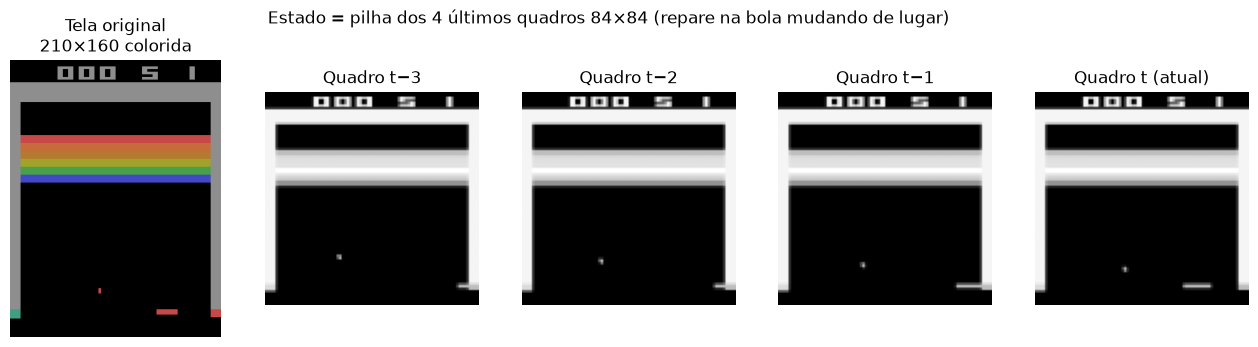

In [3]:
obs, _ = env.reset(seed=seed)
obs, *_ = env.step(1)                       # FIRE: lança a bola
for _ in range(12):
    obs, *_ = env.step(np.random.choice([2, 3]))

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
axes[0].imshow(env.render())
axes[0].set_title('Tela original\n210×160 colorida')
for k in range(4):
    axes[k + 1].imshow(np.array(obs)[k], cmap='gray')
    axes[k + 1].set_title(f'Quadro t−{3 - k}' if k < 3 else 'Quadro t (atual)')
for ax in axes:
    ax.axis('off')
plt.suptitle('Estado = pilha dos 4 últimos quadros 84×84 (repare na bola mudando de lugar)', y=1.02)
plt.show()

## 2. A rede: da tela aos valores Q

Mesma arquitetura do artigo da DeepMind: 3 camadas convolucionais (que aprendem a "enxergar" bola, raquete e tijolos) e 2 densas. A saída tem **um valor Q por ação**; o agente joga a ação de maior Q.

In [4]:
def create_q_model():
    """Rede do artigo da DeepMind: recebe (4, 84, 84) e devolve um valor Q por ação."""
    return keras.Sequential(
        [
            keras.Input(shape=(4, 84, 84)),
            # o ambiente entrega (quadros, altura, largura); a Conv2D quer (altura, largura, quadros)
            layers.Lambda(lambda tensor: keras.ops.transpose(tensor, [0, 2, 3, 1]), output_shape=(84, 84, 4)),
            # convoluções: aprendem a "enxergar" bola, raquete e tijolos
            layers.Conv2D(32, 8, strides=4, activation="relu"),
            layers.Conv2D(64, 4, strides=2, activation="relu"),
            layers.Conv2D(64, 3, strides=1, activation="relu"),
            layers.Flatten(),
            layers.Dense(512, activation="relu"),
            layers.Dense(num_actions, activation="linear"),   # um Q por ação
        ]
    )


model = create_q_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 84, 84, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 20, 20, 32)     │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 9, 9, 64)       │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,686,180 (6.43 MB)

 Trainable params: 1,686,180 (6.43 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# @title Funções para jogar, gravar GIF e consultar a rede (rode e siga em frente)
from PIL import Image as PILImage


@tf.function
def _q(modelo, estados):
    return modelo(estados, training=False)


def valores_q(modelo, estado):
    """Os 4 valores Q da rede para um estado (4, 84, 84)."""
    return _q(modelo, tf.convert_to_tensor(estado[None], dtype=tf.float32))[0].numpy()


def politica_aleatoria(estado):
    return np.random.randint(num_actions), None


def politica_da_rede(modelo, eps=0.05):
    """ε-greedy com ε pequeno (padrão em Atari): sem nenhum acaso, o agente pode travar sem apertar FIRE."""
    def politica(estado):
        q = valores_q(modelo, estado)
        a = np.random.randint(num_actions) if np.random.rand() < eps else int(np.argmax(q))
        return a, q
    return politica


def jogar(politica, max_passos=3000, seed=0, gravar_a_cada=0):
    """Joga um episódio. Devolve pontuação, quadros (para o GIF) e um histórico por passo."""
    estado, info = env.reset(seed=seed)
    vidas = info['lives']
    total, quadros = 0.0, []
    hist = {'q_max': [], 'ponto': [], 'perdeu_vida': []}
    for t in range(max_passos):
        a, q = politica(np.array(estado))
        estado, r, terminated, truncated, info = env.step(a)
        total += r
        hist['q_max'].append(None if q is None else float(np.max(q)))
        hist['ponto'].append(r > 0)
        hist['perdeu_vida'].append(info['lives'] < vidas)
        vidas = info['lives']
        if gravar_a_cada and t % gravar_a_cada == 0:
            quadros.append(env.render())
        if terminated or truncated:
            break
    return total, quadros, hist


def mostrar_gif(quadros, nome, ms_por_quadro=40, largura=320):
    """Monta um GIF com os quadros (na pasta temporária) e mostra no notebook."""
    import tempfile
    arquivo = os.path.join(tempfile.gettempdir(), nome)
    imgs = [PILImage.fromarray(q).quantize(colors=32) for q in quadros]
    imgs[0].save(arquivo, save_all=True, append_images=imgs[1:], duration=ms_por_quadro, loop=0, optimize=True)
    display(Image(filename=arquivo, width=largura))

## 3. Linha de base: um agente aleatório

Antes de olhar para o agente treinado, vejamos o que acontece apertando botões ao acaso.

> **Palpite:** quantos pontos o agente aleatório faz por partida (5 vidas)?

Agente aleatório: 1 pontos em 168 passos


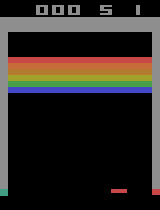

In [6]:
np.random.seed(seed)
pontos, quadros, _ = jogar(politica_aleatoria, gravar_a_cada=2)
print(f'Agente aleatório: {pontos:.0f} pontos em {len(quadros) * 2} passos')
mostrar_gif(quadros, 'breakout_aleatorio.gif')

## 4. O agente treinado

A célula abaixo baixa os pesos da rede treinada (≈ 6 MB) e os coloca no modelo que acabamos de criar — a **mesma** função `create_q_model()`.

> **Palpite:** o agente treinado aprendeu alguma "estratégia"? Observe o que acontece quando ele abre um buraco na lateral da parede de tijolos.

Rede treinada carregada.


Agente treinado: 276 pontos em 1720 passos


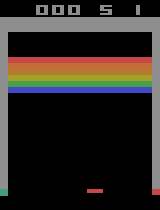

In [7]:
import urllib.request

URL_PESOS = ("https://raw.githubusercontent.com/FIAPON/fiap-aprendizado-reforco/"
             "main/models/breakout_dqn_pesos.npz")
# Rodando dentro do repositório, os pesos já estão em ../models; no Colab, baixamos do GitHub.
candidatos = [os.path.join("..", "models", "breakout_dqn_pesos.npz"), "breakout_dqn_pesos.npz"]
ARQ_PESOS = next((c for c in candidatos if os.path.exists(c)), candidatos[-1])
if not os.path.exists(ARQ_PESOS):
    print("Baixando os pesos da rede treinada...")
    urllib.request.urlretrieve(URL_PESOS, ARQ_PESOS)

pesos = np.load(ARQ_PESOS)
model.set_weights([pesos[f"arr_{i}"] for i in range(len(pesos.files))])
print("Rede treinada carregada.")

np.random.seed(seed)
pontos_dqn, quadros, hist_dqn = jogar(politica_da_rede(model), gravar_a_cada=3)
print(f"Agente treinado: {pontos_dqn:.0f} pontos em {len(hist_dqn['q_max'])} passos")
mostrar_gif(quadros, 'breakout_treinado.gif')

### O que o agente "pensa" durante a partida

A cada passo, a rede estima o valor do estado: $V(s) = \max_a Q(s,a)$ — quantos pontos (descontados) ela espera fazer daqui para frente. Abaixo, essa estimativa ao longo da partida, com os momentos em que ele **fez ponto** e em que **perdeu vida**.

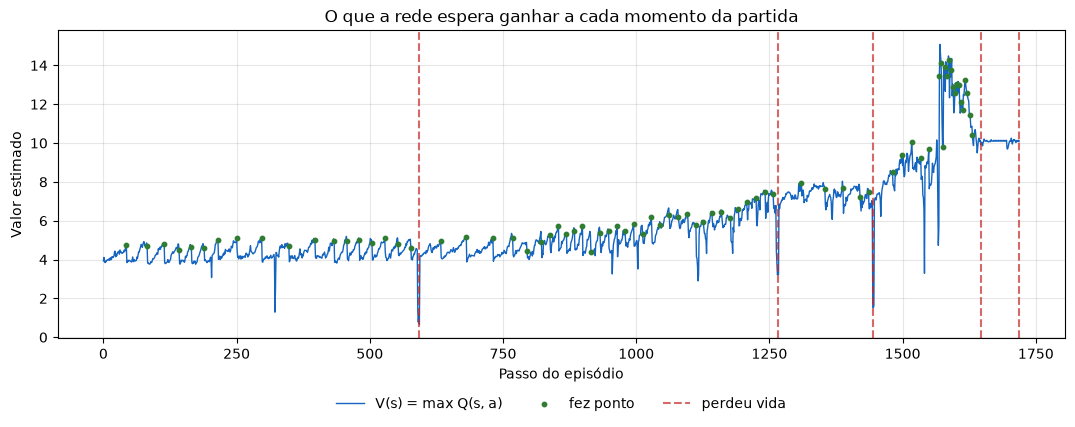

In [8]:
q_max = np.array(hist_dqn['q_max'])
t = np.arange(len(q_max))
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t, q_max, color='#1565C0', linewidth=1, label='V(s) = max Q(s, a)')
ax.scatter(t[hist_dqn['ponto']], q_max[hist_dqn['ponto']], s=10, color='#2e7d32', zorder=3, label='fez ponto')
for k, p in enumerate(np.where(hist_dqn['perdeu_vida'])[0]):
    ax.axvline(p, color='#c62828', linestyle='--', alpha=0.7, label='perdeu vida' if k == 0 else None)
ax.set_xlabel('Passo do episódio')
ax.set_ylabel('Valor estimado')
ax.set_title('O que a rede espera ganhar a cada momento da partida')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.grid(alpha=0.3)
plt.show()

**Para pensar**
1. O que acontece com o valor estimado logo antes de o agente perder uma vida? A rede "percebe" que vai errar?
2. Os pontos verdes ficam mais espaçados no fim da partida. Por quê? (dica: quantos tijolos restam?)
3. A recompensa de cada tijolo chega na hora, mas o valor V(s) olha para o futuro (γ = 0,99). Qual é a diferença entre os dois?

## 5. Avaliação: o agente aprendeu? (slide 135)

Uma partida não prova nada: pode ter sido sorte. Jogamos **10 partidas** de cada agente, com sementes diferentes, e comparamos.

In [9]:
def avaliar(politica, n_episodios=10, seed=1000):
    return [jogar(politica, seed=seed + k)[0] for k in range(n_episodios)]


np.random.seed(seed)
p_rand = avaliar(politica_aleatoria)
p_dqn = avaliar(politica_da_rede(model))
print(f"Aleatório: {p_rand} → média {np.mean(p_rand):.1f}")
print(f"DQN      : {p_dqn} → média {np.mean(p_dqn):.1f}")

Aleatório: [0.0, 1.0, 2.0, 2.0, 0.0, 0.0, 0.0, 0.0, 1.0, 2.0] → média 0.8
DQN      : [23.0, 107.0, 167.0, 52.0, 88.0, 93.0, 13.0, 261.0, 279.0, 167.0] → média 125.0


## 6. Opcional: treine o seu próprio DQN

Aqui está o ciclo completo do DQN — o mesmo que gerou a rede da seção 4, só que **muito** mais curto. Mude `TREINAR = True` para rodar.

| | `MODO_DEMO = True` (aula) | `MODO_DEMO = False` |
|---|---|---|
| Episódios | 150 (≈ 10–15 min no Colab) | até a média passar de 40 pontos (horas de GPU) |
| Só ações aleatórias | primeiros 5.000 passos | primeiros 50.000 passos |
| ε cai de 1,0 até 0,1 em | 50.000 passos | 1.000.000 de passos |
| Resultado esperado | o agente **ainda joga mal**, mas você vê o ciclo inteiro | agente competente |

> **Atenção:** com poucos episódios e a exploração longa do artigo, o agente passaria o treino inteiro jogando ao acaso — por isso o modo demonstração encurta a exploração. Não espere da demo o resultado da seção 4: a rede pré-treinada jogou **mais de 50 vezes** mais.

In [10]:
TREINAR = False   # mude para True para treinar
MODO_DEMO = True

In [11]:
from collections import deque

GAMMA = 0.99               # desconto
LOTE = 32                  # tamanho do minilote tirado do replay
MAX_MEMORIA = 100_000      # tamanho do replay (o artigo usa 1 milhão: não cabe na RAM do Colab)
TREINAR_A_CADA = 4         # uma atualização da rede a cada 4 ações
ALVO_A_CADA = 10_000       # passos entre cópias da rede principal para a rede-alvo
perda_huber = keras.losses.Huber()   # Huber: menos sensível a erros grandes que o erro quadrático


def escolher_acao(modelo, estado, epsilon):
    """ε-greedy: com probabilidade ε joga ao acaso; senão, a ação de maior Q."""
    if np.random.rand() < epsilon:
        return np.random.randint(num_actions), False
    return int(np.argmax(valores_q(modelo, estado))), True


def passo_de_treino(modelo, modelo_alvo, otimizador, memoria):
    """Sorteia um minilote do replay e aplica uma atualização de Bellman na rede principal."""
    idx = np.random.randint(len(memoria), size=LOTE)
    s, a, r, s2, fim = (np.array(x) for x in zip(*(memoria[i] for i in idx)))
    s, s2 = s.astype(np.float32), s2.astype(np.float32)

    # Alvo de Bellman com a rede-ALVO: r + γ · max Q_alvo(s', a'). Em estado terminal não há futuro.
    q_futuro = np.max(_q(modelo_alvo, s2).numpy(), axis=1)
    alvo = r + GAMMA * q_futuro * (1 - fim)

    mascara = tf.one_hot(a, num_actions)      # só a ação tomada entra no erro
    with tf.GradientTape() as tape:
        q_acao = tf.reduce_sum(modelo(s) * mascara, axis=1)
        perda = perda_huber(alvo.astype(np.float32), q_acao)
    grads = tape.gradient(perda, modelo.trainable_variables)
    otimizador.apply_gradients(zip(grads, modelo.trainable_variables))

In [12]:
def treinar_dqn(max_episodios, modo_demo=True):
    modelo, modelo_alvo = create_q_model(), create_q_model()
    modelo_alvo.set_weights(modelo.get_weights())          # a rede-alvo começa como cópia
    otimizador = keras.optimizers.Adam(learning_rate=0.00025, clipnorm=1.0)
    passos_aleatorios = 5_000 if modo_demo else 50_000     # só ações aleatórias no começo
    passos_decaimento = 50_000 if modo_demo else 1_000_000 # ε cai de 1,0 a 0,1 ao longo destes passos

    memoria = deque(maxlen=MAX_MEMORIA)                    # replay de experiências
    epsilon, passos, acoes_da_rede = 1.0, 0, 0
    recompensas = []
    episodio = 0
    while True:
        estado, _ = env.reset()
        estado = np.array(estado)
        total = 0.0
        for _ in range(10_000):
            passos += 1
            eps_agora = 1.0 if passos < passos_aleatorios else epsilon
            acao, da_rede = escolher_acao(modelo, estado, eps_agora)
            acoes_da_rede += da_rede
            epsilon = max(0.1, epsilon - 0.9 / passos_decaimento)

            prox, r, terminated, truncated, _ = env.step(acao)
            prox = np.array(prox)
            # `terminated` = fim de jogo de verdade (sem futuro). `truncated` = corte por tempo:
            # o próximo estado ainda tem futuro, então não marcamos como terminal.
            memoria.append((estado, acao, r, prox, float(terminated)))
            estado, total = prox, total + r

            if passos % TREINAR_A_CADA == 0 and len(memoria) > LOTE:
                passo_de_treino(modelo, modelo_alvo, otimizador, memoria)
            if passos % ALVO_A_CADA == 0:
                modelo_alvo.set_weights(modelo.get_weights())
            if terminated or truncated:
                break

        recompensas.append(total)
        episodio += 1
        media = np.mean(recompensas[-100:])
        if episodio % 10 == 0:
            print(f"episódio {episodio:4d} | recompensa {total:4.0f} | média (até 100 ep.) {media:5.2f} "
                  f"| ε {epsilon:.2f} | passos {passos}")
        if media > 40 or (max_episodios and episodio >= max_episodios):
            break
    print(f"\nPassos de ambiente: {passos} | ações escolhidas pela rede: {acoes_da_rede / passos:.0%}")
    return modelo, recompensas


if TREINAR:
    modelo_demo, rec_demo = treinar_dqn(150 if MODO_DEMO else 0, MODO_DEMO)
    plt.figure(figsize=(9, 3.5))
    plt.plot(rec_demo, alpha=0.4)
    plt.plot(np.convolve(rec_demo, np.ones(10) / 10, mode='valid'), linewidth=2)
    plt.xlabel('Episódio'); plt.ylabel('Pontos'); plt.title('Treino do seu DQN'); plt.grid(alpha=0.3)
    plt.show()
    np.random.seed(seed)
    print("Seu DQN (avaliação):", avaliar(politica_da_rede(modelo_demo)))
else:
    print("Treino desligado. Mude TREINAR = True na célula acima para treinar.")

Treino desligado. Mude TREINAR = True na célula acima para treinar.


## 7. Para levar

1. **Mesma ideia, outra escala:** a atualização é a do Q-Learning; a rede só substitui a tabela que não caberia na memória.
2. **Replay + rede-alvo** são o que tornam o treino estável (reveja o "mão na massa" do `dqn_scratch`).
3. **Custo:** o agente da seção 4 precisou de 1,7 milhão de passos — mais de 3 mil partidas. RL com redes neurais é caro em dados; por isso simuladores são tão importantes na prática.
4. **Avaliação:** sempre compare com uma linha de base e use várias partidas (slide 135).

**Desafio:** na seção 5, avalie a rede treinada com `eps=0.0` em `politica_da_rede(model, eps=0.0)`. O que acontece? Por que um pouquinho de acaso ajuda aqui?